# Unemployment Analysis in India (May 2019 – Jun 2020)
**CodeAlpha Data Science Internship – Task 2**

**Objectives**
1. Clean and explore the unemployment dataset
2. Visualise unemployment trends
3. Measure the impact of Covid-19 (national, state, rural vs urban)
4. Look for patterns / seasonality
5. Turn the findings into policy-relevant insights

**Columns:** `Region` (state), `Date` (month end), `Estimated Unemployment Rate (%)`, `Estimated Employed`, `Estimated Labour Participation Rate (%)`, `Area` (Rural/Urban).

## 1. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
IMG = Path("images"); IMG.mkdir(exist_ok=True)
def save(name): plt.savefig(IMG / f"{name}.png", bbox_inches="tight", dpi=150)

LOCKDOWN_START = pd.Timestamp("2020-03-25")   # nationwide lockdown began 25 Mar 2020

## 2. Load data

In [2]:
raw = pd.read_csv("data/Unemployment_in_India.csv")
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


## 3. Data cleaning
Issues found in the raw file: column names/values have **leading spaces**, `Date` is a string (dd-mm-yyyy), and there are **28 completely empty rows**.

In [3]:
df = raw.copy()
print("Empty rows       :", df.isna().all(axis=1).sum())
df = df.dropna(how="all").copy()

df.columns = df.columns.str.strip()
df = df.rename(columns={
    "Estimated Unemployment Rate (%)": "UnempRate",
    "Estimated Employed": "Employed",
    "Estimated Labour Participation Rate (%)": "LFPR",
})
for c in ["Region", "Frequency", "Area"]:
    df[c] = df[c].str.strip()
df["Date"] = pd.to_datetime(df["Date"].str.strip(), format="%d-%m-%Y")

# Derived columns: labour force and number of unemployed (needed for a weighted national rate)
df["LabourForce"] = df["Employed"] / (1 - df["UnempRate"] / 100)
df["Unemployed"]  = df["LabourForce"] - df["Employed"]
df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()

print("Clean shape      :", df.shape)
print("Missing values   :", int(df.isna().sum().sum()))
print("Duplicates       :", int(df.duplicated().sum()))
print("Date range       :", df.Date.min().date(), "->", df.Date.max().date())
print("Regions / Areas  :", df.Region.nunique(), "/", df.Area.unique().tolist())
df.info()

Empty rows       : 28
Clean shape      : (740, 10)
Missing values   : 0
Duplicates       : 0
Date range       : 2019-05-31 -> 2020-06-30
Regions / Areas  : 28 / ['Rural', 'Urban']
<class 'pandas.DataFrame'>
Index: 740 entries, 0 to 753
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Region       740 non-null    str           
 1   Date         740 non-null    datetime64[us]
 2   Frequency    740 non-null    str           
 3   UnempRate    740 non-null    float64       
 4   Employed     740 non-null    float64       
 5   LFPR         740 non-null    float64       
 6   Area         740 non-null    str           
 7   LabourForce  740 non-null    float64       
 8   Unemployed   740 non-null    float64       
 9   Month        740 non-null    datetime64[us]
dtypes: datetime64[us](2), float64(5), str(3)
memory usage: 63.6 KB


**Phase labels.** Lockdown began on 25 March 2020, so March is only partly affected. I label months as:
`Pre-Covid` (May 2019 – Feb 2020), `Transition` (Mar 2020), `Lockdown` (Apr–May 2020), `Recovery` (Jun 2020).

In [4]:
def phase(d):
    if d < pd.Timestamp("2020-03-01"): return "Pre-Covid"
    if d < pd.Timestamp("2020-04-01"): return "Transition"
    if d < pd.Timestamp("2020-06-01"): return "Lockdown"
    return "Recovery"
df["Phase"] = df["Date"].apply(phase)
order = ["Pre-Covid", "Transition", "Lockdown", "Recovery"]
df["Phase"] = pd.Categorical(df["Phase"], order, ordered=True)
df.groupby("Phase", observed=True).size().to_frame("rows")

,rows
Phase,
Pre-Covid,536
Transition,52
Lockdown,102
Recovery,50


## 4. Exploratory analysis

In [5]:
df[["UnempRate", "Employed", "LFPR"]].describe().round(2)

,UnempRate,Employed,LFPR
count,740.00,740.00,740.00
mean,11.79,7204460.03,42.63
std,10.72,8087988.43,8.11
min,0.00,49420.00,13.33
25%,4.66,1190404.50,38.06
50%,8.35,4744178.50,41.16
75%,15.89,11275489.50,45.50
max,76.74,45777509.00,72.57


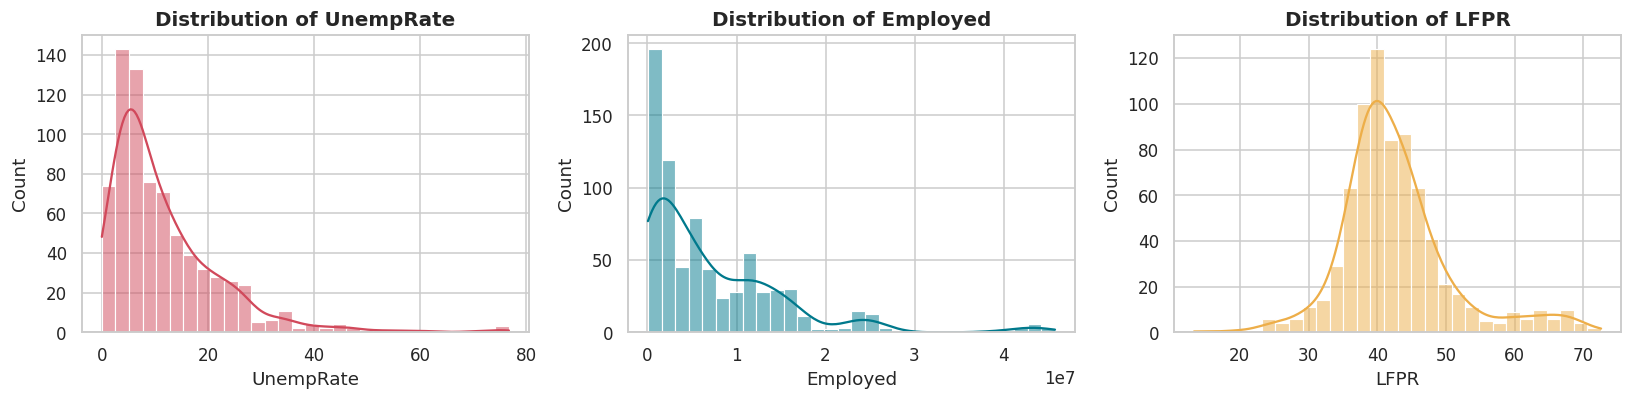

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, col, c in zip(ax, ["UnempRate", "Employed", "LFPR"], ["#d1495b", "#00798c", "#edae49"]):
    sns.histplot(df[col], bins=30, ax=a, color=c, kde=True)
    a.set_title(f"Distribution of {col}")
plt.tight_layout(); save("01_distributions"); plt.show()

`UnempRate` is strongly right-skewed: most state-months sit below ~15%, but lockdown months create a long tail up to ~77%.

## 5. National trend
Taking a simple average of state rates over-weights small states. A better national estimate is
**total unemployed ÷ total labour force** (a labour-force-weighted rate). I show both.

In [7]:
nat = df.groupby("Month").agg(Unemployed=("Unemployed", "sum"),
                              LabourForce=("LabourForce", "sum"),
                              Employed=("Employed", "sum"),
                              SimpleAvg=("UnempRate", "mean"),
                              LFPR=("LFPR", "mean"),
                              rows=("UnempRate", "size"))
nat["WeightedRate"] = nat.Unemployed / nat.LabourForce * 100
nat[["WeightedRate", "SimpleAvg", "LFPR", "rows"]].round(2)

,WeightedRate,SimpleAvg,LFPR,rows
Month,,,,
2019-05-01,7.04,8.87,43.90,54
2019-06-01,7.88,9.30,43.75,54
2019-07-01,7.37,9.03,43.71,54
2019-08-01,8.08,9.64,43.65,53
2019-09-01,7.08,9.05,44.30,52
2019-10-01,8.11,9.90,44.00,55
2019-11-01,7.25,9.87,44.11,55
2019-12-01,7.73,9.50,43.67,53
2020-01-01,7.24,9.95,44.05,53


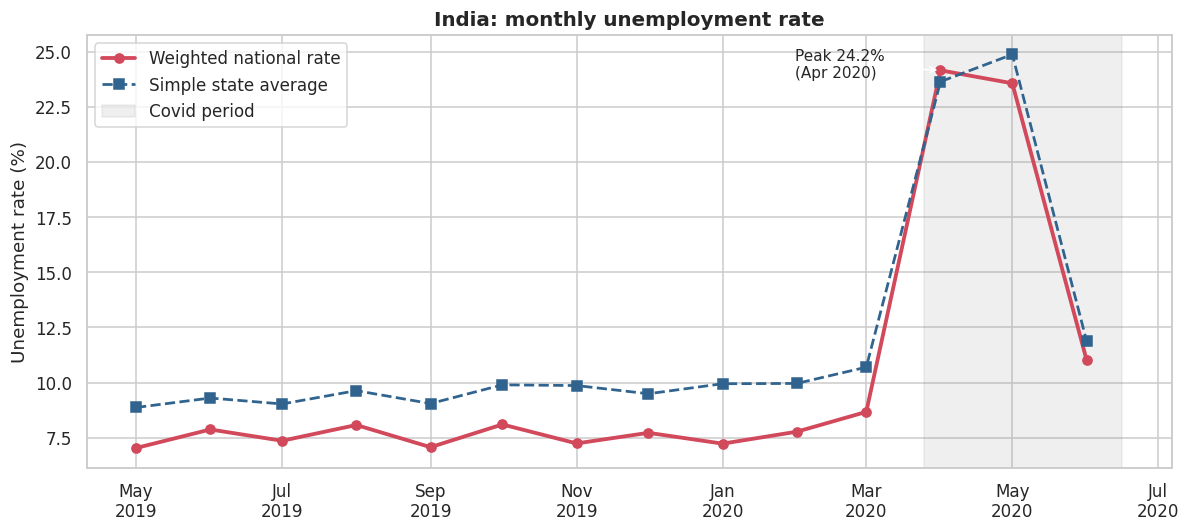

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(nat.index, nat.WeightedRate, marker="o", lw=2.5, color="#d1495b", label="Weighted national rate")
ax.plot(nat.index, nat.SimpleAvg, marker="s", lw=1.8, ls="--", color="#30638e", label="Simple state average")
ax.axvspan(pd.Timestamp("2020-03-25"), nat.index.max() + pd.Timedelta(days=15), color="grey", alpha=.12, label="Covid period")
pk = nat.WeightedRate.idxmax()
ax.annotate(f"Peak {nat.WeightedRate.max():.1f}%\n({pk:%b %Y})", (pk, nat.WeightedRate.max()),
            xytext=(-95, -5), textcoords="offset points", arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set(title="India: monthly unemployment rate", ylabel="Unemployment rate (%)", xlabel="")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y")); ax.legend(loc="upper left")
plt.tight_layout(); save("02_national_trend"); plt.show()

## 6. Impact of Covid-19

In [9]:
pre  = nat.loc[:"2020-02-29", "WeightedRate"].mean()
peak = nat.WeightedRate.max()
jun  = nat.loc["2020-06-01", "WeightedRate"]
print(f"Pre-Covid average (May19-Feb20): {pre:5.2f}%")
print(f"Peak (Apr 2020)                : {peak:5.2f}%   -> {peak/pre:.1f}x the baseline, +{peak-pre:.1f} pp")
print(f"June 2020 (recovery)           : {jun:5.2f}%   -> still +{jun-pre:.1f} pp above baseline")

# Jobs lost: compare ONLY region-area pairs observed in both months (avoids coverage bias)
piv = df.pivot_table(index=["Region", "Area"], columns="Month", values="Employed")
for end in ["2020-04-01", "2020-06-01"]:
    m = piv[[pd.Timestamp("2020-02-01"), pd.Timestamp(end)]].dropna()
    s = m.sum()
    print(f"Employed Feb->{end[:7]}: {s.iloc[0]/1e6:6.1f}M -> {s.iloc[1]/1e6:6.1f}M  ({(s.iloc[1]/s.iloc[0]-1)*100:+.1f}%)  [{len(m)} matched region-areas]")

Pre-Covid average (May19-Feb20):  7.55%
Peak (Apr 2020)                : 24.16%   -> 3.2x the baseline, +16.6 pp
June 2020 (recovery)           : 11.04%   -> still +3.5 pp above baseline
Employed Feb->2020-04:  391.0M ->  269.2M  (-31.1%)  [49 matched region-areas]
Employed Feb->2020-06:  401.1M ->  369.1M  (-8.0%)  [48 matched region-areas]


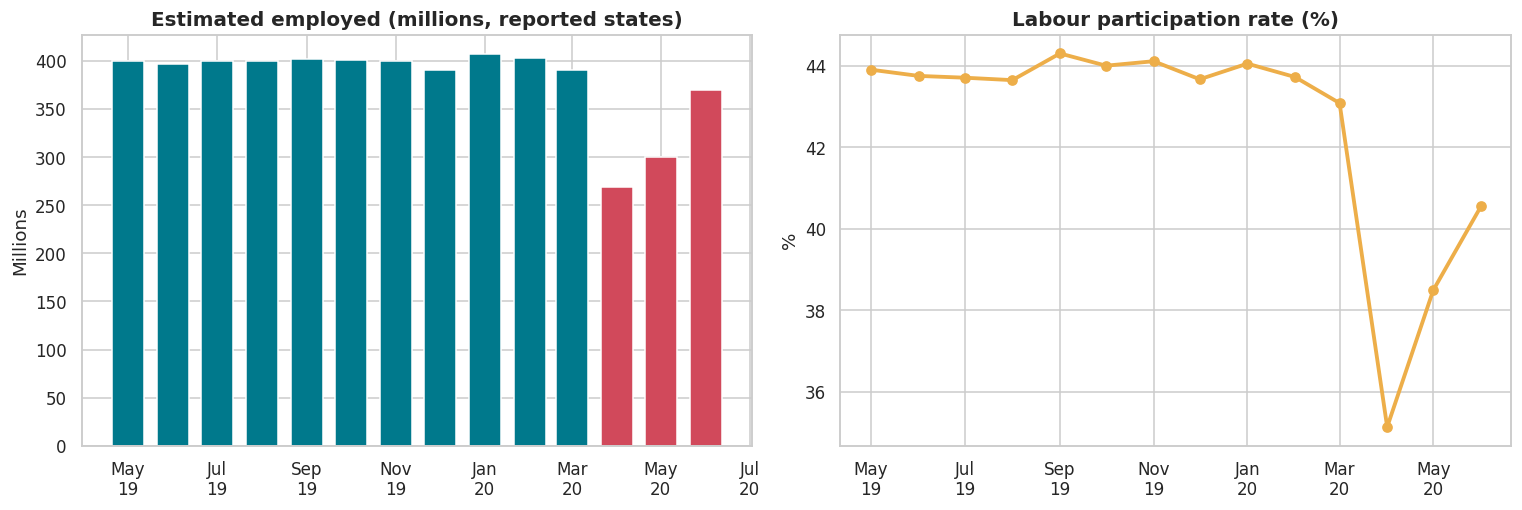

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].bar(nat.index, nat.Employed / 1e6, width=22, color=np.where(nat.index >= "2020-04-01", "#d1495b", "#00798c"))
ax[0].set(title="Estimated employed (millions, reported states)", ylabel="Millions")
ax[1].plot(nat.index, nat.LFPR, marker="o", color="#edae49", lw=2.5)
ax[1].set(title="Labour participation rate (%)", ylabel="%")
for a in ax: a.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%y"))
plt.tight_layout(); save("03_employed_lfpr"); plt.show()

Employment collapsed in April and participation fell sharply too — many people did not just lose jobs, they **stopped looking** (the labour force itself shrank), which a headline unemployment rate alone understates.

### 6.1 Rural vs Urban

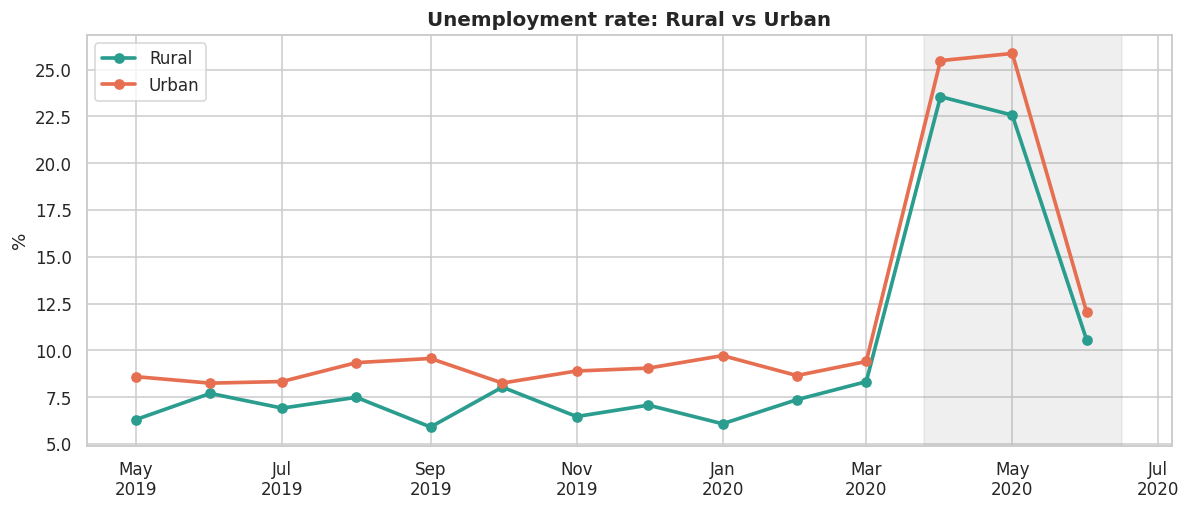

Month,2019-05-01,2019-06-01,2019-07-01,2019-08-01,2019-09-01,2019-10-01,2019-11-01,2019-12-01,2020-01-01,2020-02-01,2020-03-01,2020-04-01,2020-05-01,2020-06-01
Area,,,,,,,,,,,,,,
Rural,6.31,7.70,6.92,7.49,5.91,8.04,6.46,7.07,6.08,7.36,8.33,23.56,22.57,10.58
Urban,8.59,8.25,8.34,9.35,9.57,8.25,8.90,9.05,9.72,8.66,9.41,25.48,25.87,12.07


In [11]:
area = (df.groupby(["Month", "Area"]).apply(lambda x: x.Unemployed.sum() / x.LabourForce.sum() * 100)
          .unstack())
fig, ax = plt.subplots(figsize=(11, 4.8))
for col, c in zip(area.columns, ["#2a9d8f", "#e76f51"]):
    ax.plot(area.index, area[col], marker="o", lw=2.4, label=col, color=c)
ax.axvspan(LOCKDOWN_START, area.index.max() + pd.Timedelta(days=15), color="grey", alpha=.12)
ax.set(title="Unemployment rate: Rural vs Urban", ylabel="%", xlabel="")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y")); ax.legend()
plt.tight_layout(); save("04_rural_urban"); plt.show()
area.round(2).T

### 6.2 State-level impact

In [12]:
sp = df.pivot_table(index="Region", columns="Month", values="UnempRate")
state = pd.DataFrame({
    "PreCovid": sp.loc[:, :"2020-02-01"].mean(axis=1),
    "LockdownPeak": sp.loc[:, ["2020-04-01", "2020-05-01"]].mean(axis=1),
}).dropna()
state["Increase_pp"] = state.LockdownPeak - state.PreCovid
state = state.sort_values("Increase_pp", ascending=False)
state.round(1).head(10)

,PreCovid,LockdownPeak,Increase_pp
Region,,,
Puducherry,1.6,75.3,73.7
Jharkhand,14.3,57.1,42.8
Tamil Nadu,2.8,40.9,38.0
Bihar,13.8,47.2,33.4
Karnataka,3.2,24.5,21.2
Haryana,22.9,40.3,17.4
Madhya Pradesh,4.7,21.8,17.1
Andhra Pradesh,5.0,22.0,17.0
Telangana,4.7,21.4,16.7


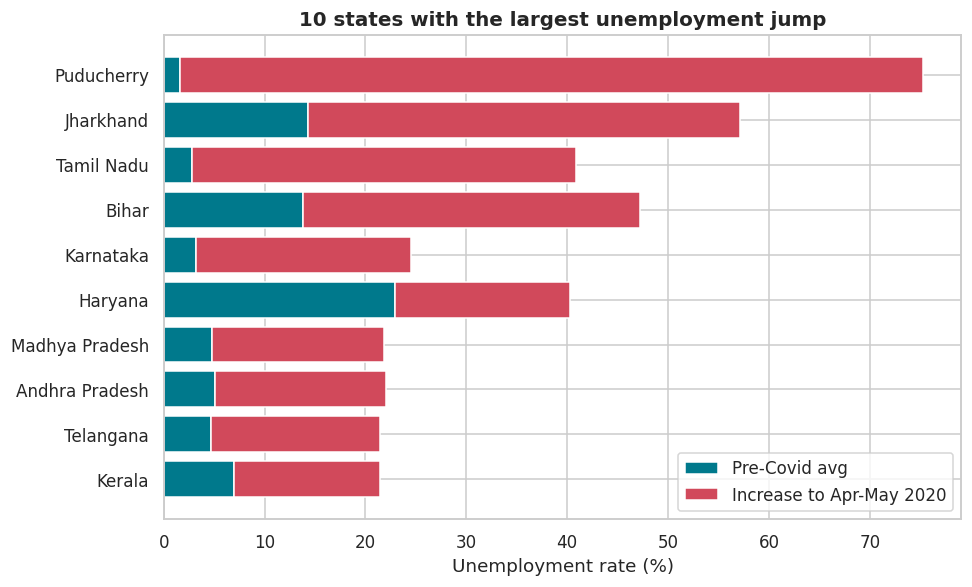

In [13]:
top = state.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index, top.PreCovid, color="#00798c", label="Pre-Covid avg")
ax.barh(top.index, top.Increase_pp, left=top.PreCovid, color="#d1495b", label="Increase to Apr-May 2020")
ax.set(title="10 states with the largest unemployment jump", xlabel="Unemployment rate (%)")
ax.legend(loc="lower right"); plt.tight_layout(); save("05_top_states"); plt.show()

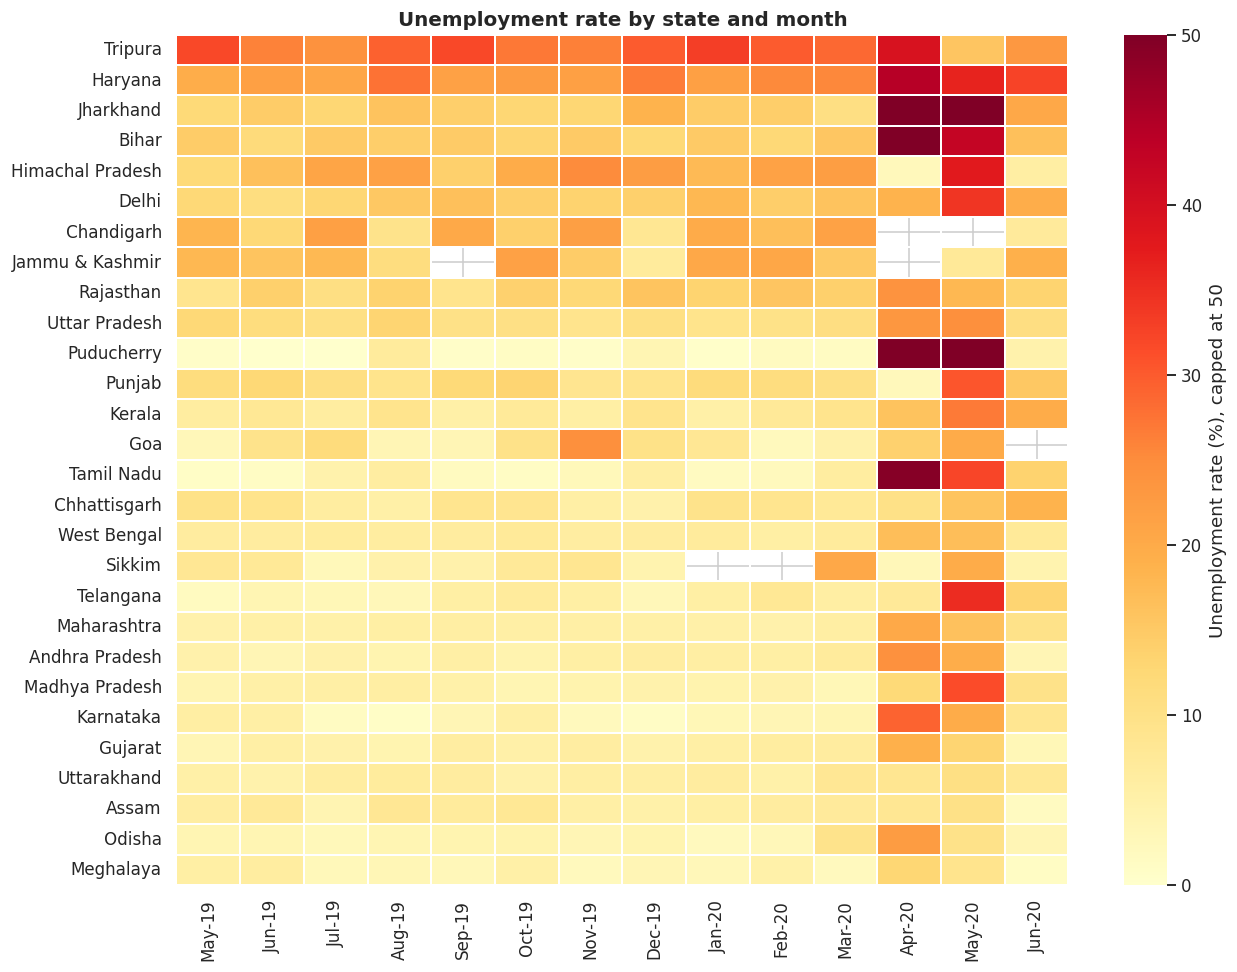

In [14]:
heat = sp.loc[sp.mean(axis=1).sort_values(ascending=False).index]
heat.columns = heat.columns.strftime("%b-%y")
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(heat, cmap="YlOrRd", annot=False, linewidths=.3, vmax=50, cbar_kws={"label": "Unemployment rate (%), capped at 50"}, ax=ax)
ax.set(title="Unemployment rate by state and month", xlabel="", ylabel="")
plt.tight_layout(); save("06_state_heatmap"); plt.show()

## 7. Patterns and seasonality
**Important limitation:** the data covers only 14 months, so each calendar month appears once (except May and June, which fall on either side of Covid). A genuine seasonal pattern needs at least 2–3 years of data, so seasonality **cannot be confirmed** here. What can be checked is the pre-Covid structure and volatility.

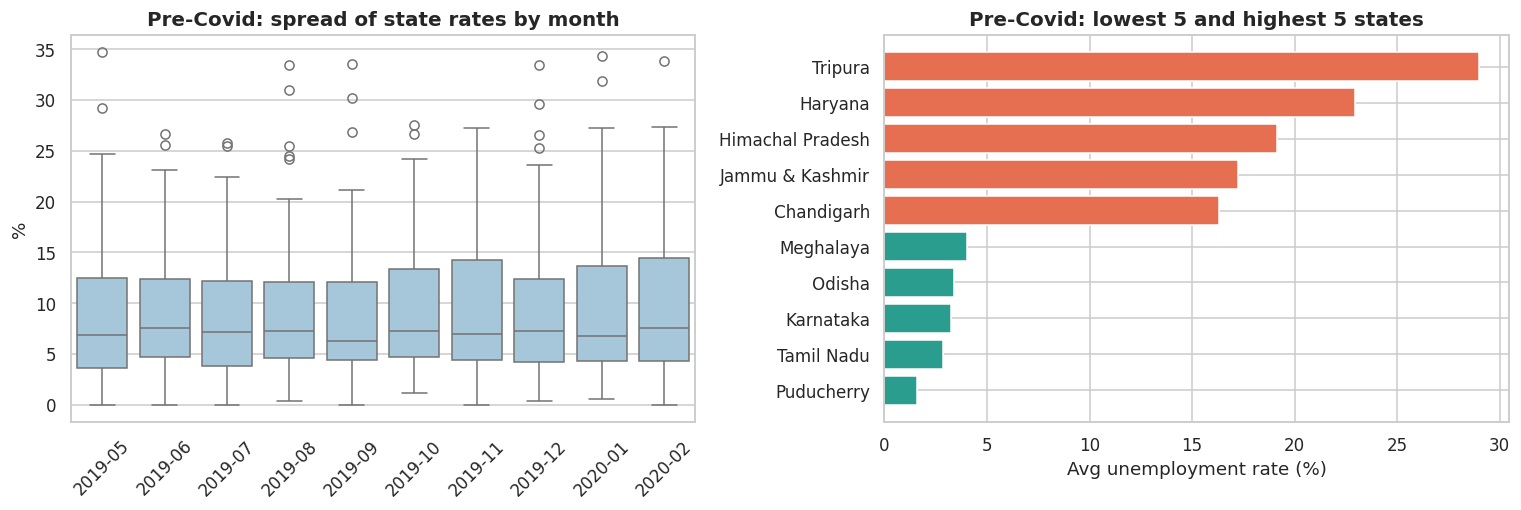

Pre-Covid weighted national rate range: 7.04% - 8.11%


In [15]:
pre_df = df[df.Phase == "Pre-Covid"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
sns.boxplot(data=pre_df, x="Month", y="UnempRate", ax=ax[0], color="#9ecae1")
ax[0].set_xticklabels([t.get_text()[:7] for t in ax[0].get_xticklabels()], rotation=45)
ax[0].set(title="Pre-Covid: spread of state rates by month", xlabel="", ylabel="%")

lvl = pre_df.groupby("Region").UnempRate.mean().sort_values()
lvl = pd.concat([lvl.head(5), lvl.tail(5)])
ax[1].barh(lvl.index, lvl.values, color=["#2a9d8f"] * 5 + ["#e76f51"] * 5)
ax[1].set(title="Pre-Covid: lowest 5 and highest 5 states", xlabel="Avg unemployment rate (%)")
plt.tight_layout(); save("07_precovid_patterns"); plt.show()

print("Pre-Covid weighted national rate range: %.2f%% - %.2f%%" %
      (nat.loc[:"2020-02-29", "WeightedRate"].min(), nat.loc[:"2020-02-29", "WeightedRate"].max()))

### 7.1 Is unemployment related to participation / employment?

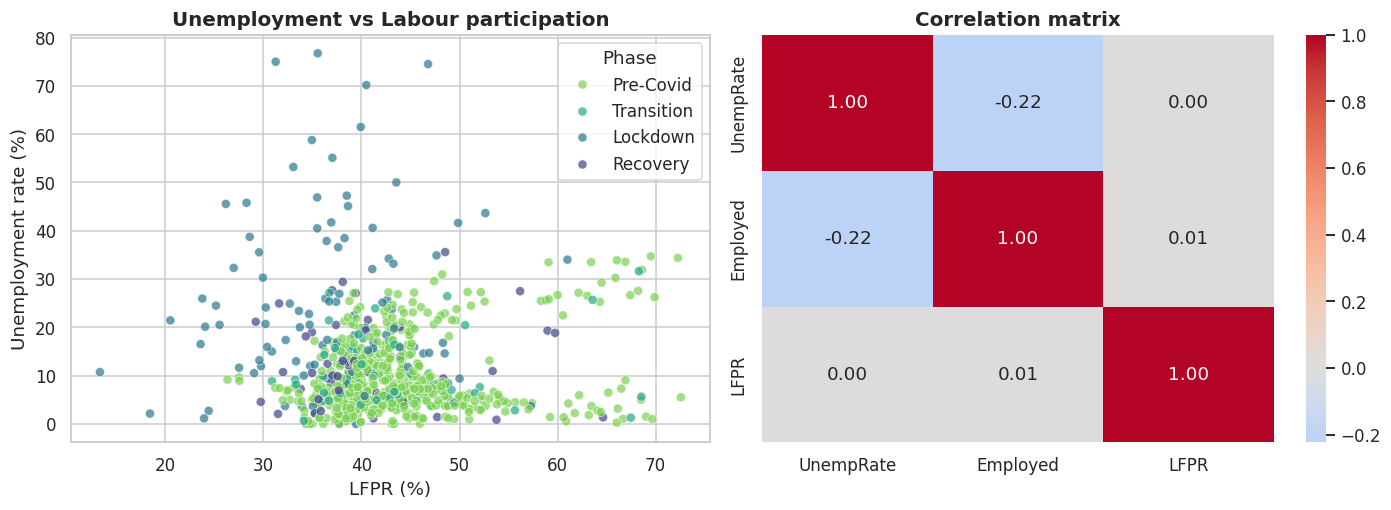

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sns.scatterplot(data=df, x="LFPR", y="UnempRate", hue="Phase", palette="viridis_r", alpha=.7, ax=ax[0])
ax[0].set(title="Unemployment vs Labour participation", xlabel="LFPR (%)", ylabel="Unemployment rate (%)")
sns.heatmap(df[["UnempRate", "Employed", "LFPR"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1])
ax[1].set_title("Correlation matrix")
plt.tight_layout(); save("08_relationships"); plt.show()

Correlations are weak overall because state size (`Employed`) and the lockdown shock dominate. The relationship is better understood phase by phase than as one pooled number.

### 7.2 Data-quality flags worth knowing

In [17]:
print("State-months with 0% unemployment:", int((df.UnempRate == 0).sum()))
print(df.loc[df.UnempRate == 0, ["Region", "Month", "Area"]].assign(Month=lambda d: d.Month.dt.strftime("%b-%y")).to_string(index=False))
print()
print("Highest 5 readings:")
print(df.nlargest(5, "UnempRate")[["Region", "Area", "Month", "UnempRate"]].assign(Month=lambda d: d.Month.dt.strftime("%b-%y")).to_string(index=False))
print()
print("Months of data per region-area (min/max):", df.groupby(["Region", "Area"]).size().min(), "/", df.groupby(["Region", "Area"]).size().max())

State-months with 0% unemployment: 11
      Region  Month  Area
       Assam Jun-20 Rural
Chhattisgarh Apr-20 Rural
         Goa Feb-20 Rural
  Puducherry May-19 Rural
  Puducherry Jun-19 Rural
  Puducherry Jul-19 Rural
  Puducherry Sep-19 Rural
  Puducherry Nov-19 Rural
      Sikkim Apr-20 Rural
  Puducherry Jun-19 Urban
  Puducherry Jul-19 Urban

Highest 5 readings:
    Region  Area  Month  UnempRate
Puducherry Urban Apr-20      76.74
Puducherry Urban May-20      75.00
Puducherry Rural Apr-20      74.51
 Jharkhand Urban May-20      70.17
 Jharkhand Urban Apr-20      61.48

Months of data per region-area (min/max): 5 / 14


## 8. Key insights

**What the data shows**

1. **Baseline (May 2019 – Feb 2020):** the labour-force-weighted national rate stayed in a narrow band of about **7.0–8.1%** (average 7.6%; the simple state average is higher, ~9.5%). Month-to-month moves were small.
2. **Covid shock:** the rate jumped to **24.2% in April 2020** (3.2x baseline, +16.6 pp). Among region-areas observed in both months, employment fell about **31% from Feb to Apr 2020**, and labour participation dropped from ~43.7% to ~35.1%, so many people left the labour force entirely rather than being counted as unemployed.
3. **Partial recovery:** by June 2020 the rate fell to **11.0%**, but was still ~3.5 pp above baseline; employment was still ~8% below February and participation (~40.6%) had not recovered.
4. **Urban vs rural:** urban unemployment was already higher before Covid (~9% vs ~7%) and was hit harder in the lockdown (~25.5–25.9% vs ~22.6–23.6% in Apr–May). Rural areas recovered slightly faster (10.6% vs 12.1% in June).
5. **States:** the biggest increases were in **Puducherry, Jharkhand, Tamil Nadu and Bihar**. Some states had high unemployment even *before* Covid (**Tripura, Haryana, Himachal Pradesh**), so their problem is structural, not only Covid-driven.
6. **Seasonality:** with only 14 months of data, **no seasonal pattern can be established**. Pre-Covid months move within a narrow range with no clear cycle.

**Policy implications** (my interpretation of the patterns, not causal proof)

- **Urban job support** (urban employment programmes, support for informal and gig workers) deserves attention, since urban areas were hit hardest.
- **States with a high baseline** (Haryana, Tripura, Jharkhand, Bihar) need longer-term job creation and skilling, not only emergency relief.
- **Track participation, not only unemployment.** The fall in the labour participation rate shows that the headline rate understated the damage in April.
- **Pre-positioned safety nets** (rural job guarantee, income support, migrant-worker coverage) can cushion sudden shocks like a lockdown.

**Limitations**
- Only 14 months, no multi-year comparison, so seasonality is untestable.
- 28 blank rows removed; some states have missing months (e.g. Chandigarh, Sikkim, J&K), so state peaks are indicative.
- A few extreme or zero values (notably Puducherry) suggest small-sample or measurement noise and should be treated with caution.
- "Employed" figures cover the surveyed regions in this file, so they illustrate relative change and are not an exact national job-loss count.